# 참조 사진의 자세를 그대로, 사람만 바꾸기 (OpenPose + ControlNet)

사진 한 장을 주면 그 사람의 **관절 위치**를 뽑아내고, 그 뼈대를 그대로 유지한 채
**다른 사람 · 다른 옷 · 다른 배경**으로 새 그림을 만듭니다.

## 무슨 일이 일어나는가

```
참조 사진          뼈대(스켈레톤)         새 그림
 (요가 자세)   →    ┌─ 머리              (같은 자세의
  사람 A            │  어깨─팔            다른 사람)
                    └─ 허리─다리
                 OpenPose 가 뽑음    ControlNet 이 이 뼈대를
                                     지키라고 강제함
```

**마네킹에 옷을 갈아입히는 것**과 같습니다. 포즈를 잡은 마네킹(뼈대)은 그대로 두고,
겉모습만 프롬프트로 바꿔 끼웁니다.

---

## 쓰는 부품

| 역할 | 무엇 | 하는 일 |
|---|---|---|
| **자세 추출기** | OpenPose (`controlnet_aux`) | 사진에서 관절 18개를 찾아 막대 그림으로 그림 |
| **자세 강제기** | ControlNet (OpenPose용) | 그림을 만드는 내내 "이 뼈대에서 벗어나지 마" 라고 붙잡음 |
| **그림 그리는 모델** | SDXL | 프롬프트대로 실제 그림을 그림 |

---

## FLUX.2-klein 4B 를 안 쓴 이유

**ControlNet 은 모델 구조마다 따로 만들어야 합니다.** SDXL용 ControlNet 을 FLUX 에
끼울 수 없습니다. 그런데

- 나와 있는 FLUX.2 계열 ControlNet 은 **klein 9B** 또는 **FLUX.2-dev** 용입니다
- 옆 노트북이 쓰는 **klein 4B GGUF Q4** 에 맞는 것은 아직 없습니다
- 무료 T4(VRAM 15GB)에 FLUX 본체와 ControlNet 을 같이 올리면 메모리가 빠듯합니다

그래서 **SDXL + OpenPose ControlNet** 으로 만들었습니다. **원리와 순서는 완전히 같습니다** —
나중에 더 좋은 GPU 를 쓰게 되면 그리는 모델만 바꿔 끼우면 됩니다.

---

## 시작하기 전에

상단 메뉴 **[런타임 → 런타임 유형 변경 → T4 GPU]** 선택 후 저장.
그다음 아래 칸을 **위에서부터 순서대로** 실행하세요.

## [단계 0] GPU 가 붙었는지 확인

이 실습은 GPU 없이는 안 됩니다. 아래 칸을 실행해 `Tesla T4` 같은 이름이 보이면 준비된 것입니다.

In [ ]:
!pip install --upgrade pip
!pip uninstall -y mediapipe controlnet_aux protobuf
!pip install -q diffusers transformers accelerate safetensors controlnet_aux mediapipe --upgrade protobuf
import os
print("설치 완료! 메모리를 비우기 위해 런타임을 강제로 재시작합니다...")
os.kill(os.getpid(), 9)
os.kill(os.getpid(), 9)
os.kill(os.getpid(), 9)
import urllib.request
import torch

print("PyTorch:", torch.__version__)
print("CUDA 사용 가능:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM(GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
else:
    raise RuntimeError("GPU 가 없습니다. [런타임 → 런타임 유형 변경 → T4 GPU] 후 다시 실행하세요.")

Found existing installation: mediapipe 0.10.30
Uninstalling mediapipe-0.10.30:
  Successfully uninstalled mediapipe-0.10.30
Found existing installation: controlnet_aux 0.0.10
Uninstalling controlnet_aux-0.0.10:
  Successfully uninstalled controlnet_aux-0.0.10
Found existing installation: protobuf 3.20.3
Uninstalling protobuf-3.20.3:
  Successfully uninstalled protobuf-3.20.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.36.1 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.1 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.36.1 which is incompatible.


## [단계 1] 필요한 것 설치

- `diffusers` — 그림 모델을 다루는 라이브러리
- `controlnet_aux` — **OpenPose 같은 "전처리기" 모음.** 사진에서 뼈대를 뽑는 도구가 여기 들어 있습니다
- `mediapipe` — OpenPose 가 속으로 쓰는 부품

2분쯤 걸립니다. 설치 중 빨간 경고가 몇 줄 나와도 대개 괜찮습니다.

In [2]:
import sys

!{sys.executable} -m pip uninstall -y mediapipe
!pip install -q diffusers transformers accelerate safetensors controlnet_aux mediapipe

print("설치 완료")

Found existing installation: mediapipe 1.0.1
Uninstalling mediapipe-1.0.1:
  Successfully uninstalled mediapipe-1.0.1
설치 완료


## [단계 2] 참조 사진 올리기

**자세를 빌려올 사진**을 씁니다. 이 노트북은 `sportimg.jpg` 를 기본으로 찾습니다.

좋은 참조 사진의 조건:

- **사람이 한 명만** 나온 사진 (여럿이면 뼈대가 섞입니다)
- **몸이 잘리지 않은** 사진 (팔다리가 화면 밖으로 나가면 그 관절을 못 찾습니다)
- 배경이 복잡해도 상관없습니다 — 어차피 뼈대만 씁니다

**사진을 Colab 에 올리는 방법 (둘 중 하나)**

1. 왼쪽 **파일** 탭(폴더 아이콘) 을 열고 `sportimg.jpg` 를 그 안으로 끌어다 놓기
   → 아래 칸을 실행하면 자동으로 찾아 씁니다
2. 그냥 아래 칸을 실행 — 파일이 없으면 **파일 선택** 창이 뜹니다. 그때 `sportimg.jpg` 를 고르세요
   (내 컴퓨터의 `C:\AI-Agent\Report\0915_image\sportimg.jpg`)

둘 다 취소/실패하면 예시 사진으로 진행합니다.</cell id="cell-5">

sportimg.jpg 을(를) 작업 폴더에서 찾았습니다. 이걸 씁니다.
sportimg.jpg · 520x693


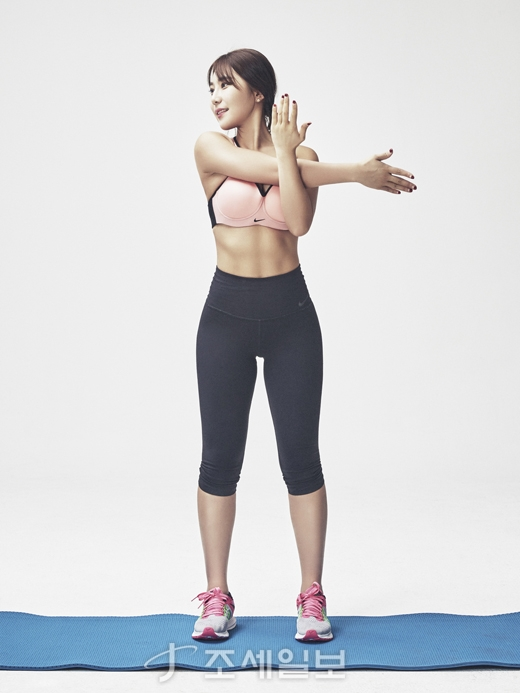

In [1]:

from pathlib import Path

from PIL import Image

DEFAULT_NAME = "sportimg.jpg"

if Path(DEFAULT_NAME).exists():
    # 파일 탭으로 미리 올려 둔 경우 (또는 이전 실행에서 이미 받아 둔 경우)
    ref_path = Path(DEFAULT_NAME)
    print(f"{DEFAULT_NAME} 을(를) 작업 폴더에서 찾았습니다. 이걸 씁니다.")
else:
    from google.colab import files

    print(f"작업 폴더에 {DEFAULT_NAME} 이(가) 없습니다. 업로드 창을 엽니다. (취소하면 예시 사진을 씁니다)")
    uploaded = files.upload()

    if uploaded:
        ref_path = Path(list(uploaded.keys())[0])
    else:
        ref_path = Path("reference.png")
        urllib.request.urlretrieve(
            "https://huggingface.co/datasets/huggingface/documentation-images/"
            "resolve/main/diffusers/person.png",
            ref_path,
        )
        print("예시 사진을 받았습니다.")

ref_image = Image.open(ref_path).convert("RGB")
print(f"{ref_path.name} · {ref_image.size[0]}x{ref_image.size[1]}")
ref_image


## [단계 3] 크기 맞추기

SDXL 은 가로·세로가 **64의 배수**일 때 가장 잘 그립니다. 아무 크기나 넣으면 결과가 뭉개지거나
메모리가 터집니다.

그래서 긴 변을 1024 로 맞추되 **원본 비율은 그대로 두고** 64 단위로 반올림합니다.
(세로 사진을 억지로 정사각형으로 늘이면 사람이 뚱뚱해집니다.)

맞춘 크기: (576, 768)


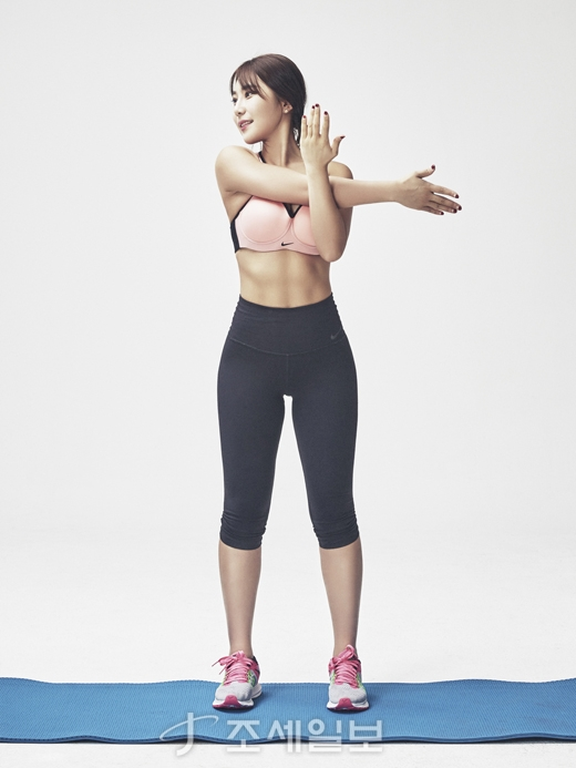

In [2]:
def fit(img, longest=768, multiple=64):
    """비율은 지키고, 긴 변을 longest 에 맞춰 64 배수 크기로 줄인다."""
    w, h = img.size
    scale = longest / max(w, h)
    nw = max(multiple, round(w * scale / multiple) * multiple)
    nh = max(multiple, round(h * scale / multiple) * multiple)
    return img.resize((nw, nh), Image.LANCZOS)


ref_fit = fit(ref_image)
print("맞춘 크기:", ref_fit.size)
ref_fit

## [단계 4] OpenPose 로 관절 뽑기

여기가 이 실습의 핵심입니다.

OpenPose 는 사진에서 **관절 18개**(코, 목, 양 어깨·팔꿈치·손목, 양 엉덩이·무릎·발목, 눈·귀)를
찾아 점으로 찍고, 이어서 **색색의 막대 그림**으로 그려 줍니다.

이 막대 그림이 다음 단계에서 "설계도" 역할을 합니다. **원래 사진의 얼굴·옷·배경은 여기서
완전히 버려집니다** — 그래서 사람을 바꿀 수 있는 것입니다.

처음 실행하면 OpenPose 가중치를 내려받느라 1분쯤 걸립니다.

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
/usr/local/lib/python3.13/dist-packages/controlnet_aux/segment_anything/modeling/tiny_vit_sam.py:654: UserWarning: Overwriting tiny_vit_5m_224 in registry with controlnet_aux.segment_anything.modeling.tiny_vit_sam.tiny_vit_5m_224. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  return register_model(fn_wrapper)
/usr/local/lib/python3.13/dist-packages/controlnet_aux/segment_anything/mode

✅ 라이브러리 충돌 우회 성공! 뼈대를 추출합니다...


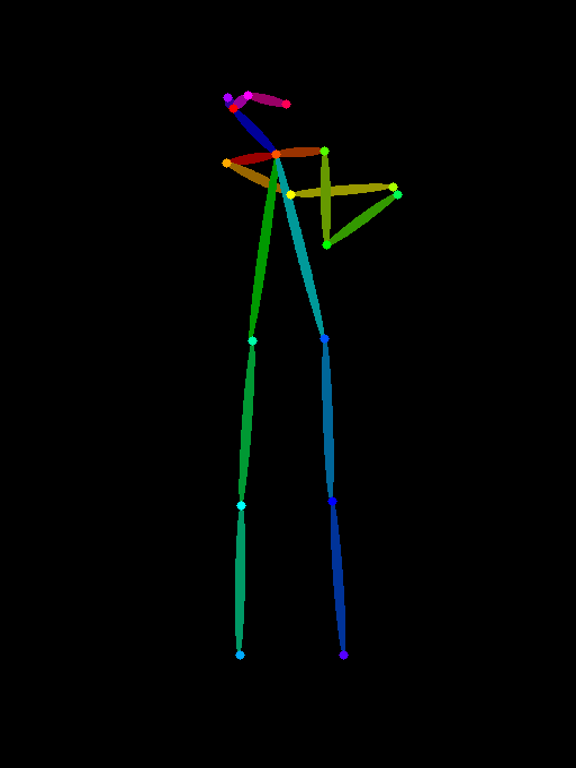

In [3]:
import sys
from unittest.mock import MagicMock

# 고장 난 mediapipe가 남아있다면 메모리에서 삭제
if 'mediapipe' in sys.modules:
    del sys.modules['mediapipe']

# 에러 구간을 건너뛰기 위해 가짜(Mock) 모듈 주입
sys.modules['mediapipe'] = MagicMock()

# 이제 에러 없이 정상적으로 불러와집니다.
from controlnet_aux import OpenposeDetector
print("✅ 라이브러리 충돌 우회 성공! 뼈대를 추출합니다...")

openpose = OpenposeDetector.from_pretrained("lllyasviel/ControlNet")
pose_image = openpose(ref_fit)
pose_image = pose_image.resize(ref_fit.size)
pose_image

### 원본과 뼈대를 나란히 보기

**여기서 반드시 확인하세요.** 뼈대가 엉뚱하게 그려졌으면 뒤 단계를 아무리 잘해도 소용없습니다.

- 막대가 거의 안 보인다 → 사람을 못 찾은 것. 다른 사진으로 바꾸세요
- 팔다리가 몸통에 붙어 버렸다 → 자세가 너무 특이하거나 가려진 것
- 뼈대가 둘 이상 그려졌다 → 사진에 사람이 여럿. 한 명만 나온 사진을 쓰세요

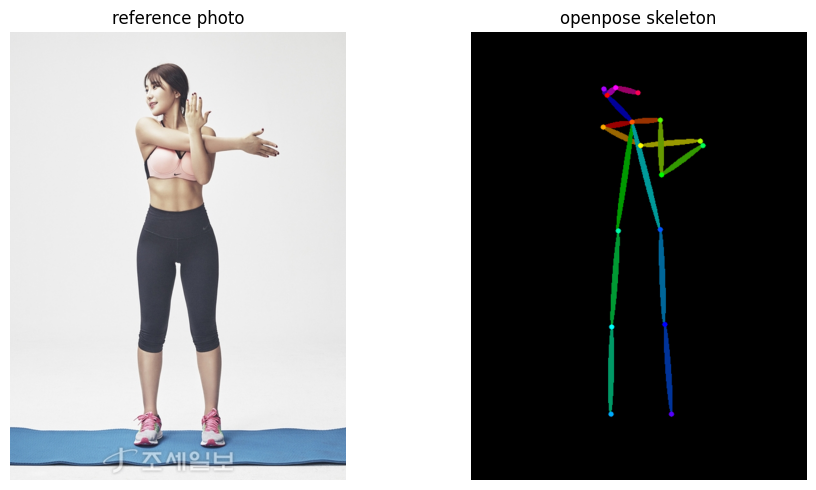

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(ref_fit);     ax[0].set_title("reference photo"); ax[0].axis("off")
ax[1].imshow(pose_image);  ax[1].set_title("openpose skeleton"); ax[1].axis("off")
plt.tight_layout()
plt.show()

## [단계 5] 모델 올리기 (SDXL + ControlNet)

세 덩어리를 올립니다. 처음 실행하면 **7GB 가량 내려받느라 5분쯤** 걸립니다.
두 번째부터는 빠릅니다.

| 무엇 | 크기 | 하는 일 |
|---|---|---|
| SDXL base | 약 7GB | 실제로 그림을 그림 |
| OpenPose ControlNet | 약 2.5GB | 뼈대를 지키도록 붙잡음 |
| VAE (fp16 수정본) | 약 300MB | 마지막에 픽셀로 바꿈 |

**VAE 를 따로 지정하는 이유**: SDXL 기본 VAE 는 float16 에서 결과가 **새까맣게** 나오는
알려진 문제가 있습니다. 고쳐 놓은 것을 씁니다.

`enable_model_cpu_offload()` 는 당장 안 쓰는 덩어리를 CPU 로 잠깐 내려 두는 기능입니다.
T4 의 15GB 안에 욱여넣기 위해 필요합니다.

In [5]:
import torch
from diffusers import AutoencoderKL, ControlNetModel, StableDiffusionXLControlNetPipeline

controlnet = ControlNetModel.from_pretrained(
    "thibaud/controlnet-openpose-sdxl-1.0", torch_dtype=torch.float16
)
vae = AutoencoderKL.from_pretrained(
    "madebyollin/sdxl-vae-fp16-fix", torch_dtype=torch.float16
)
pipe = StableDiffusionXLControlNetPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    controlnet=controlnet,
    vae=vae,
    torch_dtype=torch.float16,
    variant="fp16",
)
pipe.enable_model_cpu_offload()  # T4 메모리에 맞추기 위해
print("준비 완료")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
An error occurred while trying to fetch thibaud/controlnet-openpose-sdxl-1.0: thibaud/controlnet-openpose-sdxl-1.0 does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

준비 완료


## [단계 6] 한 장 만들어 보기

이제 프롬프트만 바꾸면 **같은 자세의 다른 사람**이 나옵니다.

### 손잡이 네 개

| 값 | 뜻 | 권장 |
|---|---|---|
| `POSE_STRENGTH` | 뼈대를 얼마나 세게 따를지 | **0.8** — 1.0 은 너무 뻣뻣, 0.5 아래는 자세가 흐트러짐 |
| `STEPS` | 그리는 횟수 | 25. 늘리면 조금 나아지고 느려짐 |
| `SEED` | 같은 값이면 같은 그림 | 아무 숫자 |
| `NEGATIVE` | 빼고 싶은 것 | 손·글자 문제를 줄여 줍니다 |

`PROMPT` 에 **자세를 다시 쓰지 마세요.** 자세는 뼈대가 담당합니다.
프롬프트에는 **누구인지, 무엇을 입었는지, 어디인지**만 씁니다.

  0%|          | 0/25 [00:00<?, ?it/s]

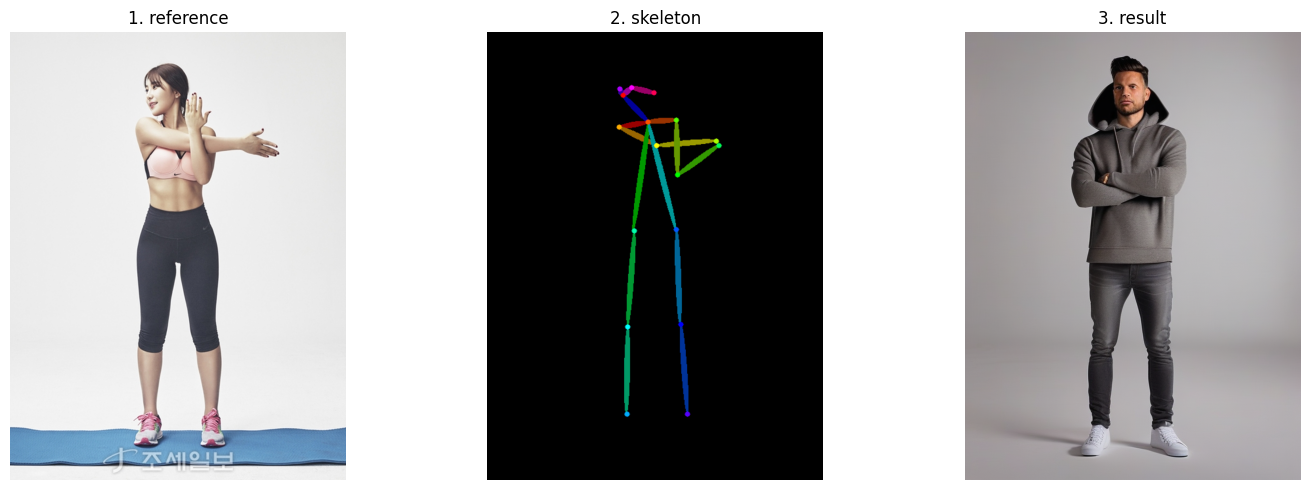

In [6]:


import matplotlib.pyplot as plt
import torch

PROMPT = "a young man in a grey hoodie and jeans, bright photo studio, plain white background, photorealistic"
NEGATIVE = "low quality, blurry, deformed hands, extra limbs, extra fingers, watermark, text"

POSE_STRENGTH = 0.8
STEPS = 25
SEED = 42

image = pipe(
    prompt=PROMPT,
    negative_prompt=NEGATIVE,
    image=pose_image,
    controlnet_conditioning_scale=POSE_STRENGTH,
    num_inference_steps=STEPS,
    generator=torch.manual_seed(SEED),
).images[0]

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(ref_fit);    ax[0].set_title("1. reference"); ax[0].axis("off")
ax[1].imshow(pose_image); ax[1].set_title("2. skeleton");  ax[1].axis("off")
ax[2].imshow(image);      ax[2].set_title("3. result");    ax[2].axis("off")
plt.tight_layout()
plt.show()

## [단계 7] 같은 자세로 여러 명 만들기

앞 노트북(`batch_image_gen`)에서 배운 것을 그대로 씁니다. **표에 줄을 적으면 한꺼번에 나옵니다.**

다른 점은 하나뿐입니다 — **뼈대가 전부 같습니다.** 그래서 자세는 똑같고 사람만 바뀝니다.

`id` 로 시드를 만들기 때문에 **같은 표를 내일 다시 돌려도 같은 그림**이 나옵니다.
그림 옆에 `.json` 으로 프롬프트·시드·모델을 함께 남깁니다.

In [ ]:
import hashlib
import json
from pathlib import Path

# 메모리를 가장 아끼기 위해 1명만 먼저 실행합니다!
PEOPLE = [
    ("man-hoodie", "a young man in a grey hoodie and jeans, photorealistic"),
]
BACKDROP = "bright photo studio, plain light grey background"

OUT_DIR = Path("out_pose")
OUT_DIR.mkdir(exist_ok=True)

def seed_from_id(name):
    return int.from_bytes(hashlib.sha256(name.encode("utf-8")).digest()[:4], "big")

results, failed = [], []
for n, (name, who) in enumerate(PEOPLE, 1):
    try:
        prompt = f"{who}, {BACKDROP}"
        seed = seed_from_id(name)
        img = pipe(
            prompt=prompt,
            negative_prompt=NEGATIVE,
            image=pose_image,
            controlnet_conditioning_scale=POSE_STRENGTH,
            num_inference_steps=STEPS,
            generator=torch.manual_seed(seed),
        ).images[0]
        img.save(OUT_DIR / f"{name}.png")
        (OUT_DIR / f"{name}.json").write_text(json.dumps({
            "id": name,
            "prompt": prompt,
            "negative_prompt": NEGATIVE,
            "seed": seed,
            "model": "stabilityai/stable-diffusion-xl-base-1.0",
            "controlnet": "thibaud/controlnet-openpose-sdxl-1.0",
            "controlnet_conditioning_scale": POSE_STRENGTH,
            "steps": STEPS,
            "reference_image": ref_path.name,
        }, ensure_ascii=False, indent=2), encoding="utf-8")
        results.append((name, img))
        print(f"[{n}/{len(PEOPLE)}] {name}  seed={seed}")
    except Exception as e:
        failed.append((name, f"{type(e).__name__}: {e}"))
        print(f"[{n}/{len(PEOPLE)}] {name}  실패 — 건너뜁니다")

print(f"끝났습니다. 성공 {len(results)} · 실패 {len(failed)}")
for name, reason in failed:
    print(f"  {name}: {reason}")

  0%|          | 0/25 [00:00<?, ?it/s]

### 한 줄로 늘어놓고 비교

맨 왼쪽이 원본 뼈대입니다. 오른쪽이 전부 **같은 자세**인지 보세요.

In [2]:
cols = len(results) + 1
fig, ax = plt.subplots(1, cols, figsize=(4 * cols, 4.5))

ax[0].imshow(pose_image); ax[0].set_title("skeleton"); ax[0].axis("off")
for i, (name, img) in enumerate(results, 1):
    ax[i].imshow(img); ax[i].set_title(name); ax[i].axis("off")

plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

## [단계 8] 내려받기

코랩은 한동안 손을 안 대면 연결이 끊기고, 그때 만든 그림도 함께 사라집니다.
**마음에 드는 게 나왔으면 먼저 받아 두세요.**

In [ ]:
import shutil

shutil.make_archive("out_pose", "zip", OUT_DIR)
print("out_pose.zip", Path("out_pose.zip").stat().st_size // 1024, "KB")

files.download("out_pose.zip")

## 잘 안 될 때

| 증상 | 원인 | 고치는 법 |
|---|---|---|
| 뼈대가 안 그려짐 | 사람을 못 찾음 | 몸 전체가 나온, 한 명짜리 사진으로 바꾸세요 |
| 자세가 참조와 다름 | 뼈대를 약하게 따름 | `POSE_STRENGTH` 를 0.9~1.0 으로 올리세요 |
| 사람이 뻣뻣하고 어색함 | 뼈대를 너무 세게 따름 | `POSE_STRENGTH` 를 0.6~0.7 로 내리세요 |
| 결과가 새까맣게 나옴 | fp16 VAE 문제 | 단계 5 의 `madebyollin/sdxl-vae-fp16-fix` 가 빠졌는지 확인 |
| 손가락이 이상함 | 이 모델의 고질병 | `NEGATIVE` 에 `deformed hands, extra fingers` 를 넣으세요. 완전히는 못 없앱니다 |
| `CUDA out of memory` | 메모리 부족 | 런타임 → 세션 다시 시작 후 단계 0 부터 다시. 크기를 768 로 줄여도 됩니다 |
| 프롬프트대로 안 나옴 | 자세와 프롬프트가 충돌 | 프롬프트에 자세 설명(`sitting`, `stretching`)을 쓰지 마세요. 뼈대가 담당합니다 |

---

## 나중에 FLUX 로 바꾸고 싶다면

**단계 5 만 바꾸면 됩니다.** 앞뒤(뼈대 뽑기, 프롬프트, 배치)는 그대로입니다.

다만 무료 T4 로는 빠듯하고, FLUX.2 계열 ControlNet 은 **klein 9B / FLUX.2-dev** 용으로
나와 있습니다. ComfyUI 쪽 워크플로를 참고하세요.

- [alibaba-pai FLUX.2-dev-Fun-Controlnet-Union (ComfyUI 노드)](https://github.com/bryanmcguire/comfyui-flux2fun-controlnet)
- [FLUX.2-klein 9B pose LoRA](https://huggingface.co/thedeoxen/refcontrol-FLUX.2-klein-9B-reference-pose-lora)
- [Flux.2 Klein ControlNet depth/openpose 워크플로](https://civitai.com/models/2578291/controlnet-depth-or-openpose-flux2klein)

## 이 노트북이 쓴 모델

- [thibaud/controlnet-openpose-sdxl-1.0](https://huggingface.co/thibaud/controlnet-openpose-sdxl-1.0)
- [stabilityai/stable-diffusion-xl-base-1.0](https://huggingface.co/stabilityai/stable-diffusion-xl-base-1.0)
- [madebyollin/sdxl-vae-fp16-fix](https://huggingface.co/madebyollin/sdxl-vae-fp16-fix)